# Question 5.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from skimage import io
from skimage.metrics import adapted_rand_error, variation_of_information
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

import warnings
warnings.filterwarnings("ignore")

In [24]:
#Step 1 and 2
image_ids = ['201080', '100007', '108004']

def load_image_and_gt(img_id):
    image = io.imread(f'images/test/{img_id}.jpg')
    gt = loadmat(f'ground_truth/test/{img_id}.mat')['groundTruth']
    seg = gt[0, 0]['Segmentation'][0, 0]          # first human segmentation
    return image, seg, gt.shape[1]

data = {}
for img_id in image_ids:
    image, seg, n_human = load_image_and_gt(img_id)
    data[img_id] = (image, seg)
    print(f"{img_id}: image {image.shape}, {n_human} human segmentations, "
          f"using #1 with {len(np.unique(seg))} regions")

201080: image (321, 481, 3), 6 human segmentations, using #1 with 3 regions
100007: image (321, 481, 3), 5 human segmentations, using #1 with 5 regions
108004: image (321, 481, 3), 5 human segmentations, using #1 with 2 regions


In [25]:
# Step 3: k-means with RGB-only features, k ∈ {3, 5, 8}
k_values = [3, 5, 8]

def kmeans_segment(features, shape, k):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(features)
    return labels.reshape(shape)

def rgb_features(image):
    return np.float32(image.reshape(-1, 3)) / 255.0

rgb_segs = {}
for img_id in image_ids:
    image, _ = data[img_id]
    for k in k_values:
        rgb_segs[(img_id, k)] = kmeans_segment(rgb_features(image), image.shape[:2], k)

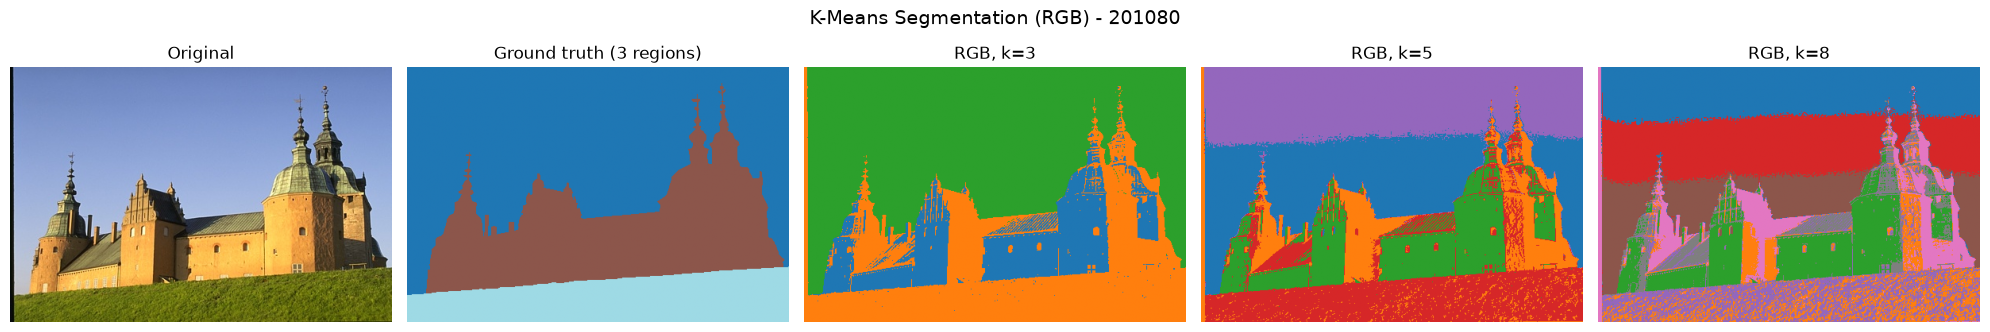

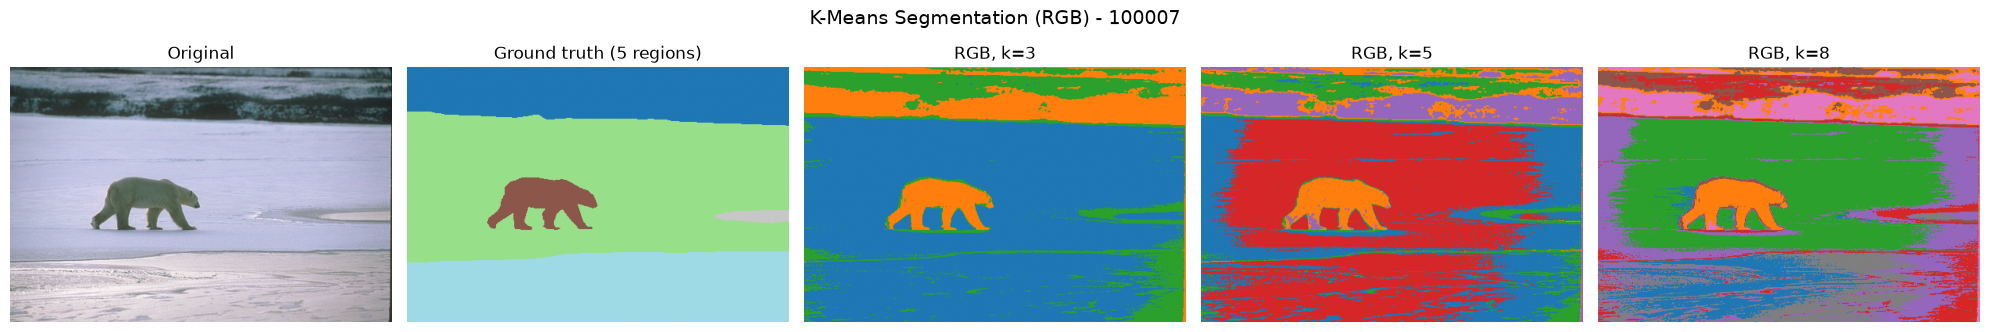

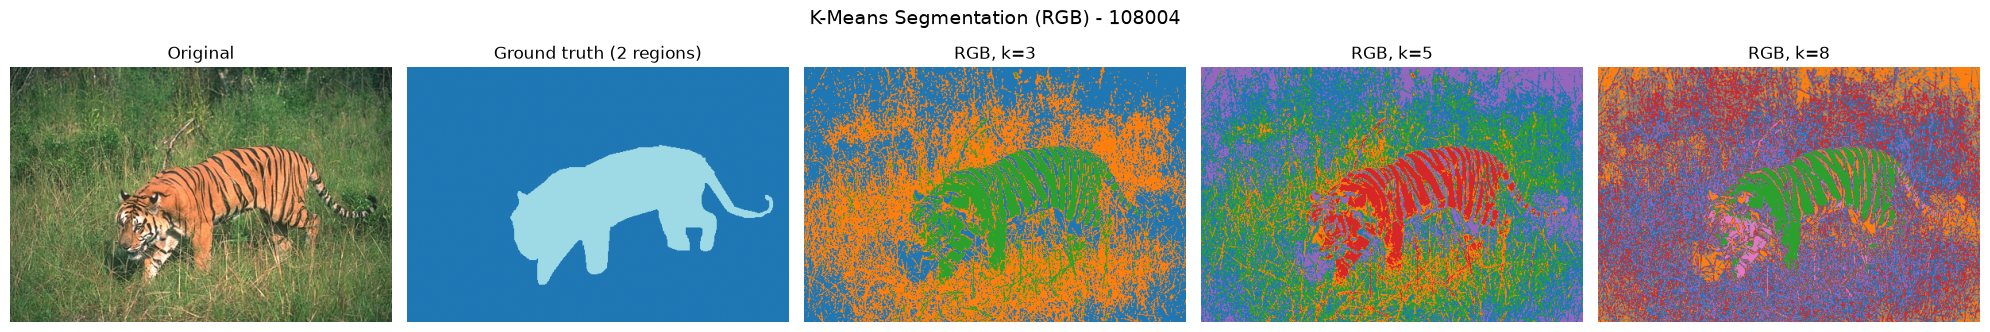

In [26]:
def show_row(img_id, segs, titles, suptitle):
    image, gt = data[img_id]
    n = 2 + len(segs)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 3.5))
    fig.suptitle(suptitle, fontsize=14)
    axes[0].imshow(image)
    axes[0].set_title("Original")
    axes[1].imshow(gt, cmap='tab20')
    axes[1].set_title(f"Ground truth ({len(np.unique(gt))} regions)")
    for ax, seg, t in zip(axes[2:], segs, titles):
        ax.imshow(seg, cmap='tab10', vmin=0, vmax=9)
        ax.set_title(t)
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

for img_id in image_ids:
    show_row(img_id, [rgb_segs[(img_id, k)] for k in k_values],
             [f"RGB, k={k}" for k in k_values], f"K-Means Segmentation (RGB) - {img_id}")

### Evaluation metrics (used in Steps 4 and 5)
* ARI: `sklearn.metrics.adjusted_rand_score` (higher is better).
* ARE: `skimage.metrics.adapted_rand_error` (lower is better).
* VI: `skimage.metrics.variation_of_information(gt, pred)` returns the two conditional entropies: **split** $= H(\text{pred}\mid\text{gt})$ (over-segmentation) and **merge** $= H(\text{gt}\mid\text{pred})$ (under-segmentation); VI = split + merge (lower is better).

In [27]:
def evaluate(gt, seg):
    ari = adjusted_rand_score(gt.ravel(), seg.ravel())
    are, _, _ = adapted_rand_error(gt, seg)
    split, merge = variation_of_information(gt, seg)
    return {'ARI': ari, 'ARE': are, 'VI split': split, 'VI merge': merge, 'VI': split + merge}

## Step 4: RGB + spatial features on image 100007 (polar bear)

**Scaling choice.** I divide RGB by 255 and divide x and y by the longer image side (481), so all features are in [0, 1] and the image is not stretched. Then I multiply x and y by a weight λ to control how much position matters compared to color. I use λ = 0.5 for the figure and also try λ = 0.1 and λ = 1 in the table.

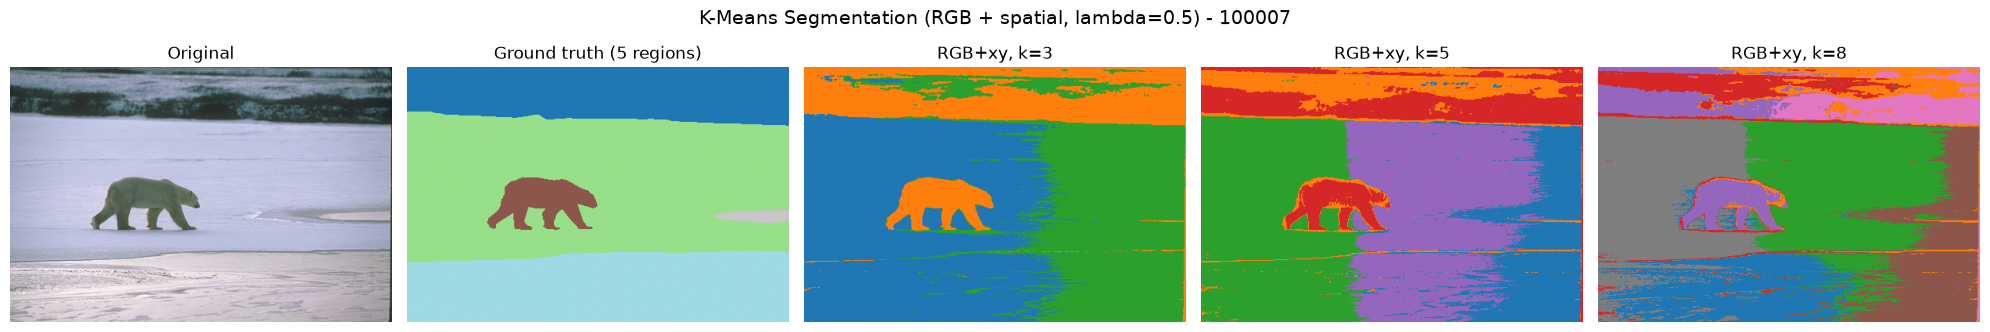

ARI    ARE  VI split  VI merge     VI
features            k                                         
RGB only            3  0.385  0.359     0.640     1.103  1.744
                    5  0.270  0.491     1.326     1.049  2.375
                    8  0.459  0.410     1.609     0.585  2.194
RGB+xy (lambda=0.1) 3  0.386  0.359     0.639     1.103  1.742
                    5  0.272  0.488     1.317     1.047  2.363
                    8  0.452  0.416     1.619     0.582  2.201
RGB+xy (lambda=0.5) 3  0.251  0.481     0.972     1.157  2.129
                    5  0.232  0.554     1.513     1.000  2.512
                    8  0.315  0.532     1.798     0.711  2.509
RGB+xy (lambda=1.0) 3  0.266  0.475     0.954     1.116  2.070
                    5  0.198  0.582     1.551     1.026  2.577
                    8  0.248  0.606     1.896     0.654  2.551

In [28]:
def rgb_xy_features(image, lam):
    H, W, _ = image.shape
    yy, xx = np.mgrid[0:H, 0:W]
    xy = np.c_[xx.ravel(), yy.ravel()] / max(H, W)    # same scale on x and y, in [0, 1]
    return np.c_[rgb_features(image), lam * xy]

spatial_id = '100007'
image, gt = data[spatial_id]
rows = []
for lam in [0.1, 0.5, 1.0]:
    segs = []
    for k in k_values:
        seg = kmeans_segment(rgb_xy_features(image, lam), image.shape[:2], k)
        segs.append(seg)
        rows.append({'features': f'RGB+xy (lambda={lam})', 'k': k, **evaluate(gt, seg)})
    if lam == 0.5:   # main setting shown as a figure; the others are in the table
        show_row(spatial_id, segs, [f"RGB+xy, k={k}" for k in k_values],
                 f"K-Means Segmentation (RGB + spatial, lambda={lam}) - {spatial_id}")

for k in k_values:
    rows.append({'features': 'RGB only', 'k': k, **evaluate(gt, rgb_segs[(spatial_id, k)])})

spatial_table = pd.DataFrame(rows).set_index(['features', 'k']).sort_index().round(3)
spatial_table

## Step 5: Evaluate RGB-only segmentations (ARI, ARE, VI)

In [29]:
rows = []
for img_id in image_ids:
    _, gt = data[img_id]
    for k in k_values:
        rows.append({'image': img_id, 'k': k, **evaluate(gt, rgb_segs[(img_id, k)])})

rgb_table = pd.DataFrame(rows).set_index(['image', 'k']).round(3)
rgb_table

ARI    ARE  VI split  VI merge     VI
image  k                                         
201080 3  0.757  0.146     0.425     0.425  0.850
       5  0.475  0.377     1.164     0.343  1.507
       8  0.345  0.516     1.746     0.294  2.041
100007 3  0.385  0.359     0.640     1.103  1.744
       5  0.270  0.491     1.326     1.049  2.375
       8  0.459  0.410     1.609     0.585  2.194
108004 3  0.170  0.408     1.242     0.482  1.724
       5  0.111  0.569     1.955     0.450  2.405
       8  0.079  0.671     2.481     0.420  2.902

## Step 6: 

**(a) How does the choice of k affect the segmentation?** 

A larger k splits the image into more, smaller color regions, so over-segmentation goes up. For the polar bear, k = 8 has the best ARI (0.459) because it needs more clusters to separate the bear, snow, water and shoreline. So the best k depends on the image.

**(b) When does RGB-only clustering fail to capture meaningful regions?** 
RGB-only clustering fails when color does not match the object. In the polar bear image, the shaded bear and the dark shoreline have the same color and end up in one cluster. Smooth lighting changes, like the sky, also get cut into bands as k grows.

**(c) In your chosen example, did adding spatial information help? Why or why not?** No,adding spatial information does not help in the polar bear case. With λ = 0.1 the scores are almost the same as RGB-only, and with λ = 0.5 or 1 they get worse for every k. Adding x and y makes k-means prefer compact blobs, so the large snow area gets cut into left and right pieces that are not real boundaries.